# Committor Model: 1D Underdamped Cosine Well, Staple Paths, Mirrored Pieces and Lag-Δ Fit

Trains `CommittorNE` on the staple run `sim_istarwell2rv` with the settings that worked on the 2D Brownian Z staple run (mirrored pieces, rejection weights) and on the well MD (a lag-Δ fit), to see whether they also fix this system.

**Why:** the earlier staple fit used forward pieces only and a lag-1 fit: RMS 0.019–0.031 against the exact q(x, v), `zqs_z` ≈ 3, with error bands along the energy contour through the bump tops (`docs/results_overview.md` II.2). On the 2D Brownian Z the mirrored pieces were required (notes §9.1); on the well MD a lag-16 fit removed the energy-contour bands (notes §10.1).

**Simulation:** `sim_istarwell2rv`: staple, cosine well (1.2 kT, two 0.15 kT bumps), Langevin γ = 1, kT = 1, dt = 0.005 (one frame per step), velocities recorded in `order.txt`. A: x ≤ −0.35, B: x ≥ 0.35.

**Exact committor:** brute-force q(x, v) on a 29 × 29 grid (`figures_by_potential/1d_cos_well/langevin_staple/checks/reference.npz`, `reference_well.py`). The grid is coarse: interpolating it gives small errors that the stopped Z_q sees at short lags (section 3).

**Results so far** (`figures_by_potential/1d_cos_well/langevin_staple/checks/run.log`, `run_rev_recorded.log`; RMS against exact over all frames with |v| < 3.5):

| Pieces | Velocity | Fit lag | RMS | max \|z\| at lags 1, 2, 4, 16, 64, 256 |
|---|---|---|---|---|
| forward | recorded | 1 | 0.019 | 0.5 0.8 0.9 1.6 2.3 2.7 |
| forward | recorded | 4 | 0.015 | 2.7 1.1 0.4 1.5 1.4 1.8 |
| forward | finite difference | 1 | 0.032 | 0.5 7.8 10.0 8.8 6.4 5.8 |
| forward | finite difference | 4 | 0.021 | 14.2 4.6 0.3 1.6 1.9 2.1 |
| forward + mirrored | recorded | 1 | 0.030 | 0.6 2.8 4.2 4.7 3.4 3.6 |
| forward + mirrored | recorded | 4 | 0.017 | 3.3 1.4 0.4 2.4 1.0 1.7 |
| forward + mirrored | finite difference | 1, 4 | not run yet | |

## 1. Imports

In [2]:
import argparse
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
from scipy.interpolate import RegularGridInterpolator

plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

REPO = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs'
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs, metrics_tis as M
import tis_data
FIG = f'{REPO}/examples/figures_by_potential'

# Figures of this notebook go to their own directory; the file names carry the run settings (TAG)
FIG_DIR = f'{REPO}/examples/figures_by_potential/1d_cos_well/langevin_staple/notebook'
os.makedirs(FIG_DIR, exist_ok=True)
def save_fig(name):
    plt.gcf().savefig(f'{FIG_DIR}/{name}.png', dpi=120, bbox_inches='tight')

## 2. Data Loading

`tis_data.prepare_data` cuts every accepted path at its first frame past M, adds the mirrored piece (the part before the last M crossing, read backwards, with the recorded velocity negated), and gives each frame its path's rejection weight. `--fd-velocity` adds a finite-difference velocity (change of x over one frame, computed on the whole path before the cut; in mirrored pieces it is computed backwards, so it is the velocity of the reversed dynamics).

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `PATHS_PER_ENSEMBLE` | 2000 | Random subset of accepted paths per ensemble, weights kept |
| `REVERSED` | True | Add the mirrored pieces (False: forward pieces only, as the earlier fit) |
| `WEIGHTS` | `rejections` | MC path weights |

Columns of `data.X`: x, recorded v, finite-difference Δx per frame.

In [3]:
TIS_DIR = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarwell2rv'
PATHS_PER_ENSEMBLE = 3000
SEED = 0
REVERSED = True
WEIGHTS = 'rejections'
DT = 0.005                         # MD time step = time per frame

parser = argparse.ArgumentParser()
tis_data.add_data_arguments(parser)
argv = [TIS_DIR, '--weights', WEIGHTS, '--paths-per-ensemble', str(PATHS_PER_ENSEMBLE), '--seed', str(SEED),
        '--fd-velocity']
if REVERSED:
    argv += ['--reversed']
data = tis_data.prepare_data(parser.parse_args(argv))

x, v_rec, v_fd = data.X[:, 0], data.X[:, 1], data.X[:, 2] / DT
b = data.boundary0 | data.boundary1
tau = M.stop_index(data.i_traj, b)             # first A/B frame or the piece's last frame
print(f'{len(x)} frames in {len(np.unique(data.i_traj))} pieces from {len(np.unique(data.group_traj))} paths')
print(f'corr(recorded v, fd v) {np.corrcoef(v_rec, v_fd)[0, 1]:.4f}, std of the difference {np.std(v_fd - v_rec):.3f}')

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/tistools/__init__.py:24: UserWarning: tistools.tica unavailable, TICA features disabled: No module named 'torch'
  warnings.warn(f"tistools.tica unavailable, TICA features disabled: {e}")


Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarwell2rv/repptis.rst: [-0.35, -0.25, -0.12, 0.12, 0.25, 0.35]
State A: order <= -0.35, state B: order >= 0.35
Found 6 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarwell2rv
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarwell2rv/001: loaded 3373 pieces, 600770 frames, total weight 5584, cut at M = -0.35
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarwell2rv/002: loaded 6000 pieces, 671339 frames, total weight 11642, cut at M = -0.25
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarwell2rv/003: loaded 6000 pieces, 1107090 frames, total weight 12524, cut at M = -0.12
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarwell2rv/004: loaded 6000 pieces, 1145739 frames, total weight 12792, cut at M = 0.12
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/s

## 3. Data Test with the Exact Committor

Before any fit: put the exact committor into the stopped Z_q of the data. For unbiased data it gives |z| ≲ 2 at every lag; if it fails, no fit on these data can be right (notes §9.1).

On this run the exact committor fails at short lags with and without the mirrored pieces (forward only: 12.0 11.1 9.6 3.5 2.5 2.1; with mirrored pieces: 15.4 14.2 12.2 5.2 2.4 2.2). The failure grows by about √2 with twice the frames, as a fixed error would, and is largest at lag 1, where small interpolation errors of the coarse 29 × 29 reference grid matter most. So it points at the reference, not at a bias of the data. At lags ≥ 64 the data pass either way.

In [4]:
ref = np.load(f'{FIG}/well_check/reference.npz')
interp = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)

def q_exact(vel):
    q = np.clip(interp(np.c_[np.clip(x, ref['xs'][0], ref['xs'][-1]), np.clip(vel, ref['vs'][0], ref['vs'][-1])]), 0, 1)
    q[data.boundary0] = 0; q[data.boundary1] = 1
    return q

LAGS = (1, 2, 4, 16, 64, 256)
def z_per_lag(r):
    """Worst |stopped Z_q / standard error| over q, per lag."""
    out = []
    for dt in LAGS:
        _, z = M.comp_zq_stopped_zscore(cp.asarray(r), b, data.i_traj, data.path_weights, dt, tau=tau,
                                        g_traj=data.group_traj)
        out.append(float(cp.max(cp.abs(z[5:]))))
    return ' '.join(f'{z:5.1f}' for z in out)

q_ref = q_exact(v_rec)                         # the truth uses the true (recorded) velocity
print(f'exact q, recorded v : max|z| at lags {LAGS}: {z_per_lag(q_ref)}')
print(f'exact q, fd v       : max|z| at lags {LAGS}: {z_per_lag(q_exact(v_fd))}')

exact q, recorded v : max|z| at lags (1, 2, 4, 16, 64, 256):  19.1  17.6  15.1   4.2   2.5   1.3
exact q, fd v       : max|z| at lags (1, 2, 4, 16, 64, 256):  23.5  12.6  13.1   3.9   1.9   1.2


## 4. Train Committor (Non-Parametric), Lag-Δ Fit

CVs (x, v) with v the recorded or the finite-difference velocity; each iteration draws one of them as the CV `y`.

**Lag-Δ fit** (notes §10.1): the library's update solves Σ_t f_k(t)[q(t+1) − q(t)] = 0 over one step. Here it is replaced by Σ_t w_t f_k(t)[q(min(t+Δ, τ_t)) − q(t)] = 0, with τ_t the first A/B frame or the last frame of the piece: windows stop at A/B or at the piece end, as in the stopped Z_q. Over one step underdamped dynamics nearly conserves energy, so errors in q that depend only on energy are almost invisible at lag 1; at lag Δ they become ~Δ times more visible. Rule of thumb γ·Δ·dt ≈ 0.05–0.1 (here Δ = 4 gives 0.02; on the MD Δ = 16 worked best). `FIT_LAG = 1` gives the library's lag-1 update. Judge a lag-Δ fit at lags ≥ Δ.

**Parameters** (as `figures_by_potential/1d_cos_well/langevin_staple/checks/well_test.py`):
| Parameter | Value | Description |
|-----------|-------|-------------|
| `VELOCITY` | `recorded` | `recorded` or `fd` (positions only) |
| `FIT_LAG` | 4 | Fit lag Δ in frames |
| `envelope_scale` | 0.01 | RC envelope width (library default) |
| `gamma` | 0.1 | Regularization (scales the step) |
| `ny` | 6 | Polynomial degree |
| `max_iter` | 4000 | Iterations |

**Seeds and warm-up** (`seed_runs.run_seeds`, shared with the other notebooks): the fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). The first `WARMUP_ITER` iterations of every seed can use their own envelope (`WARMUP_ENVELOPE`), gamma (`WARMUP_GAMMA`) and CV (`WARMUP_CV`: `None` random, otherwise the index of the CV to use); then `ENVELOPE` and `GAMMA` take over (`WARMUP_ITER = 0`: no warm-up). After the warm-up and every `CHUNK` iterations the plots in `PLOTS` are shown here and saved to `<OUT>/seed<s>/it<N>_<plot>.png`, with a progress line. The objects of earlier seeds are freed; `q` is the last seed's fit and `results[seed]['r']` every seed's RC.

**Committor map per chunk** (`seed_runs.committor_map`): after the warm-up and every chunk, the mean q per (x, v) bin (recorded v, |v| < 3.5) next to the exact committor and fit − exact, as in section 5; saved as `it<N>_q_x_v.png`.

#=500, dr2=2734.18, zqs_z=15.4913, |dx|=0.218299, time=32.4328
#=1000, dr2=2729.64, zqs_z=15.9486, |dx|=0.00166842, time=64.8365
#=1500, dr2=2728.6, zqs_z=16.1793, |dx|=0.000637843, time=97.2402
#=2000, dr2=2727.95, zqs_z=16.2121, |dx|=0.000313999, time=129.654
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_well_staple/seeds_rev_recorded_lag1/seed1/it2000 ---


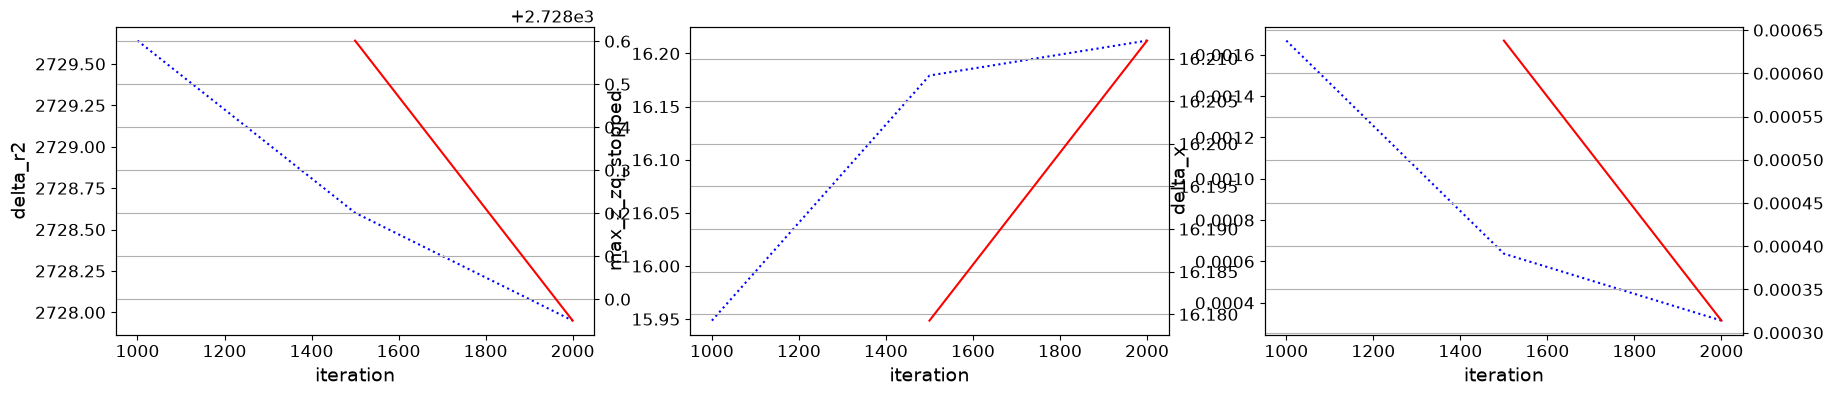

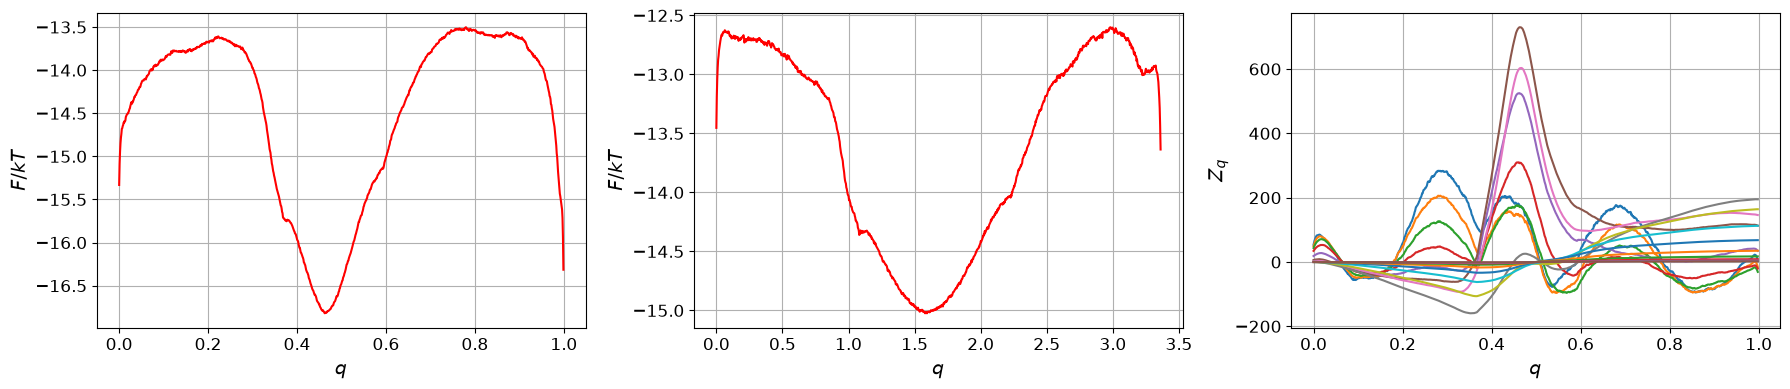

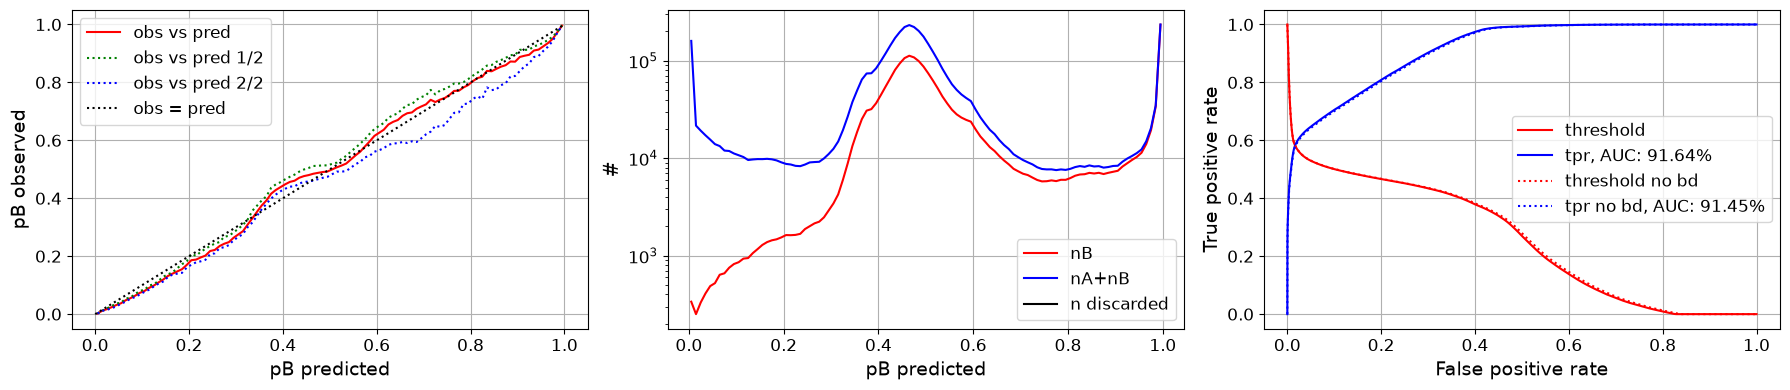

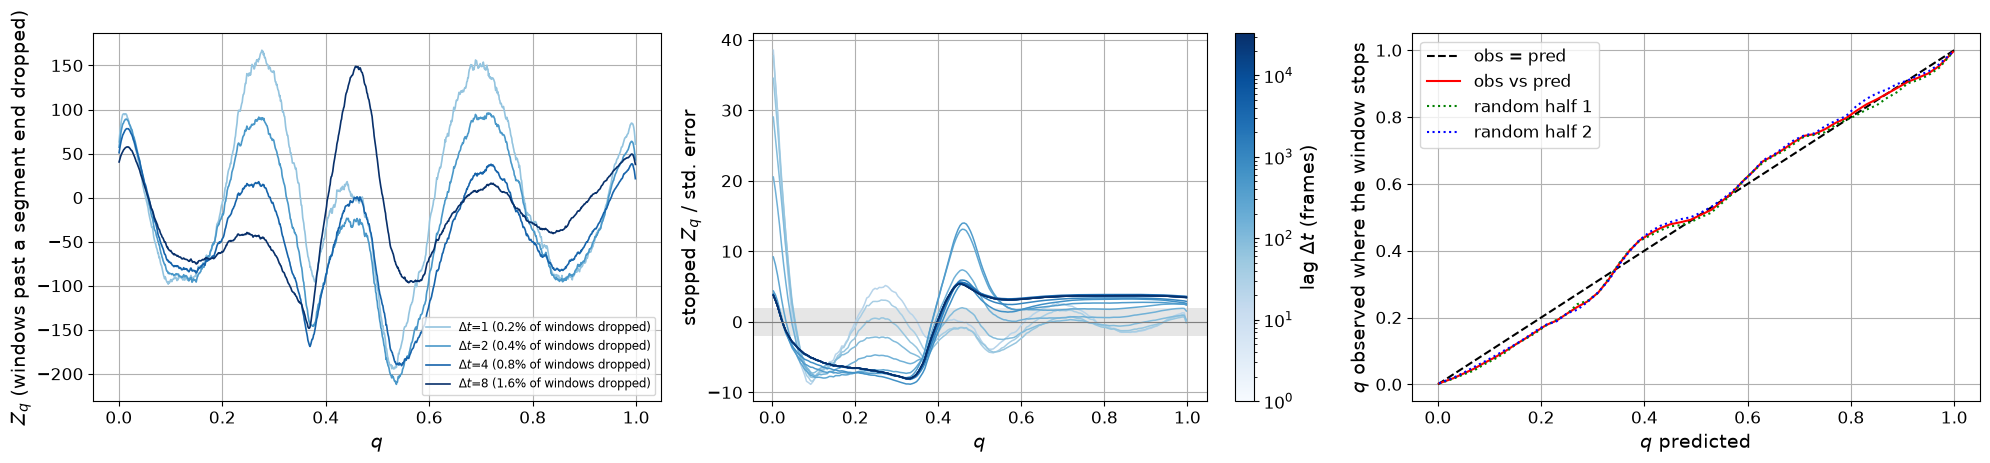

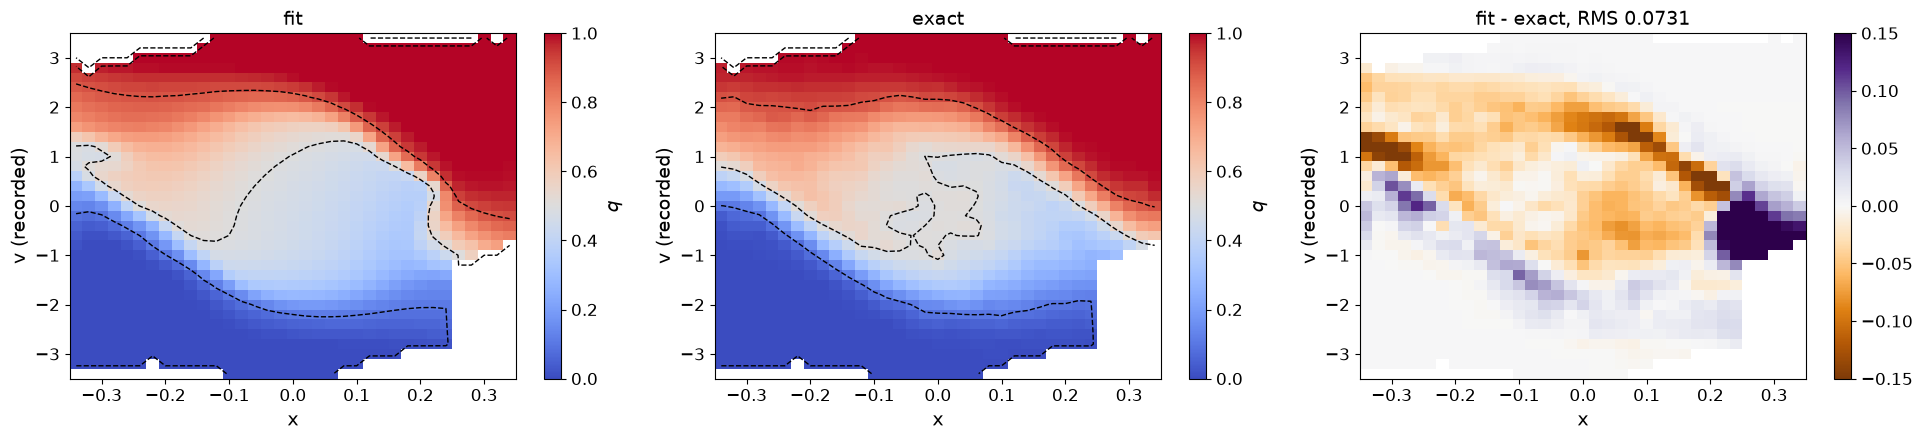

seed 1, 2000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.055 | max|z| at lags (1, 2, 4, 16, 64, 256):  14.3  16.2  16.0   8.0  14.0   8.2
#=2500, dr2=2682.05, zqs_z=5.40654, |dx|=0.0304842, time=32.3796
#=3000, dr2=2636.92, zqs_z=9.60692, |dx|=0.0442006, time=64.8651
#=3500, dr2=2594.28, zqs_z=2.58783, |dx|=0.0473989, time=97.31
#=4000, dr2=2802.18, zqs_z=10.1982, |dx|=0.0400464, time=129.752
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_well_staple/seeds_rev_recorded_lag1/seed1/it4000 ---


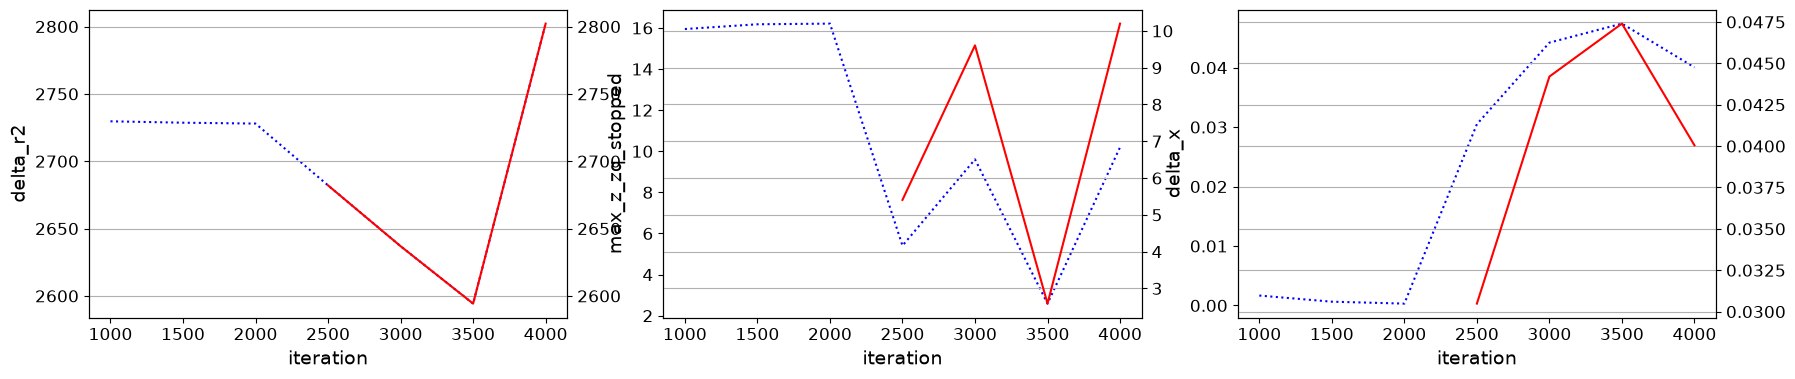

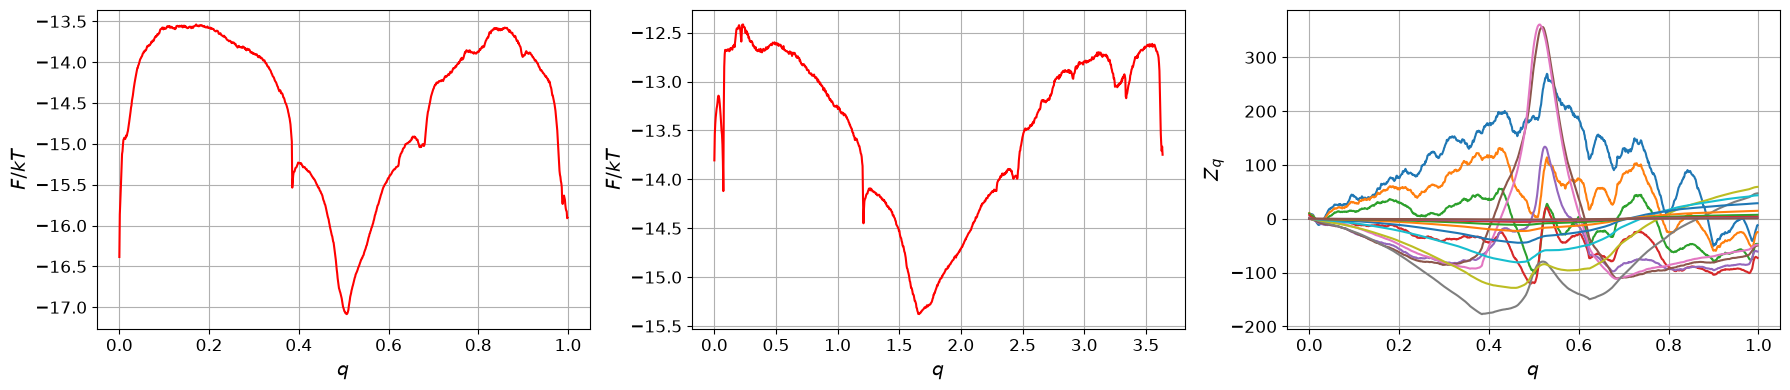

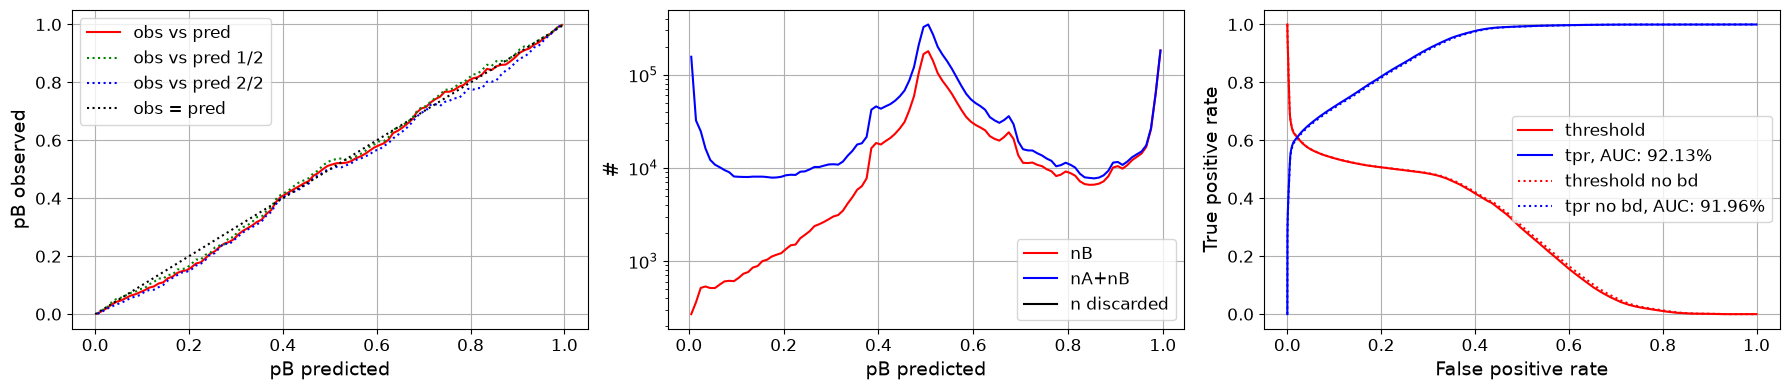

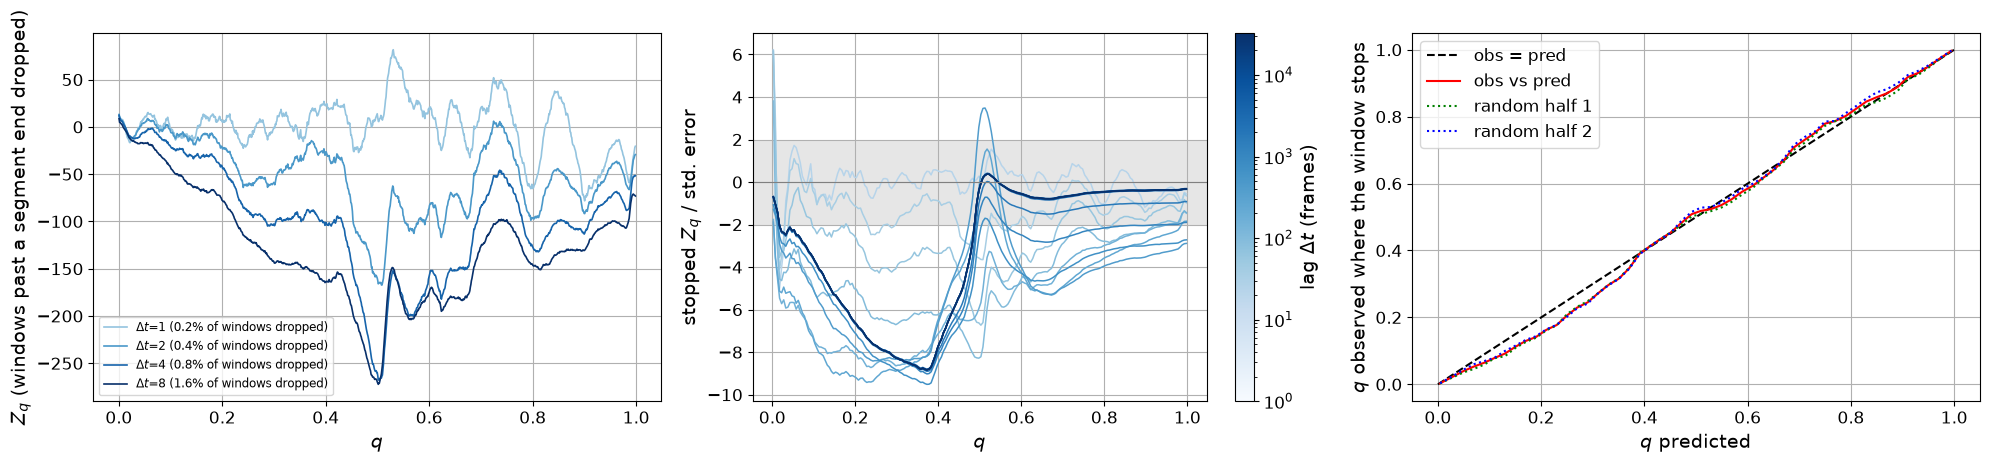

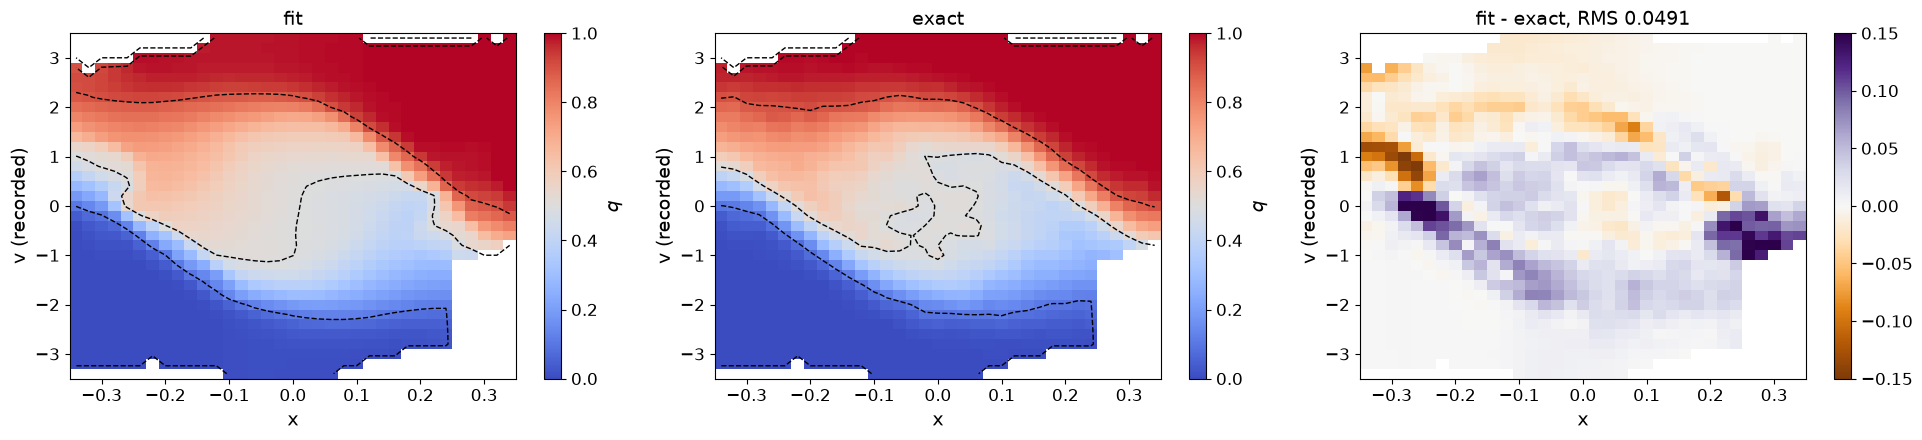

seed 1, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.039 | max|z| at lags (1, 2, 4, 16, 64, 256):   3.1   3.6   6.7   8.7   8.4   9.0
#=4500, dr2=2794.91, zqs_z=14.0118, |dx|=0.0343011, time=32.32
#=5000, dr2=2659.66, zqs_z=5.14308, |dx|=0.0214144, time=64.7644
#=5500, dr2=3046.81, zqs_z=20.9176, |dx|=0.131372, time=97.2693
#=6000, dr2=2703, zqs_z=6.58587, |dx|=0.143659, time=129.684
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_well_staple/seeds_rev_recorded_lag1/seed1/it6000 ---


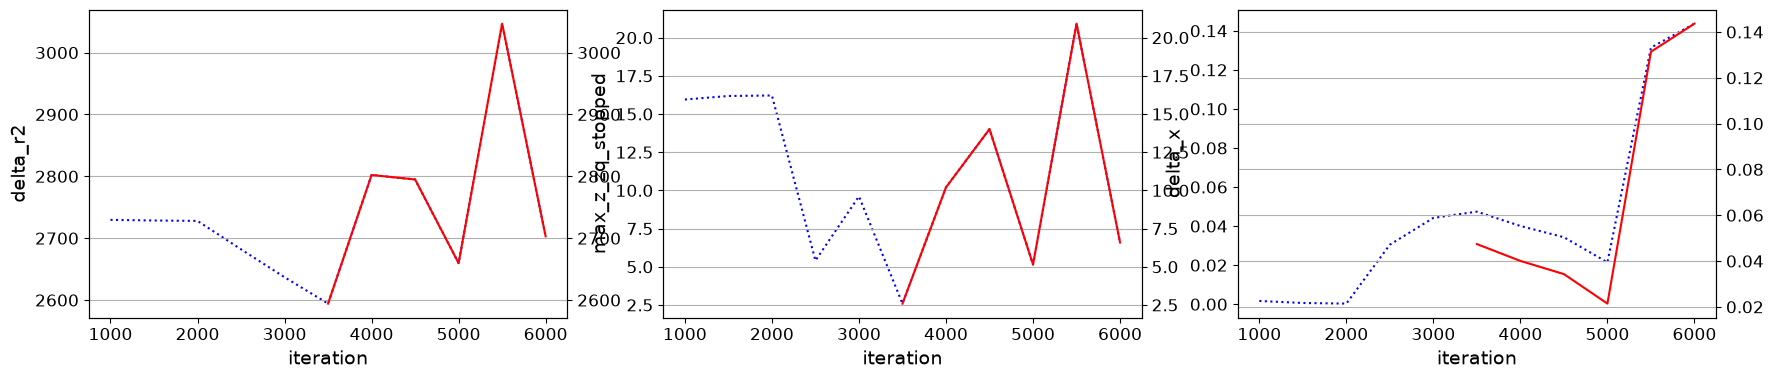

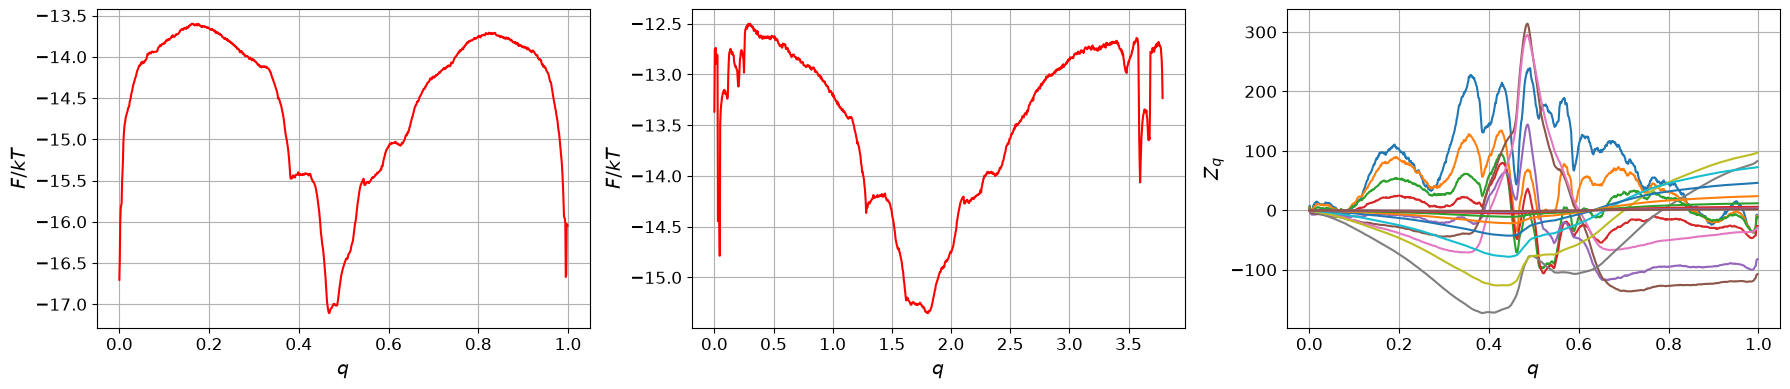

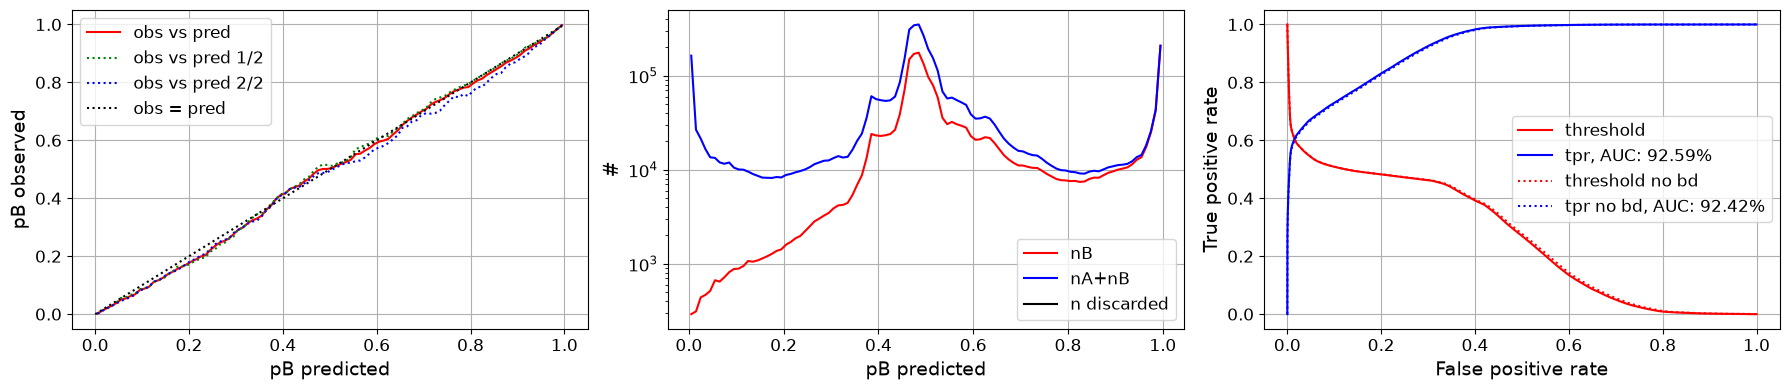

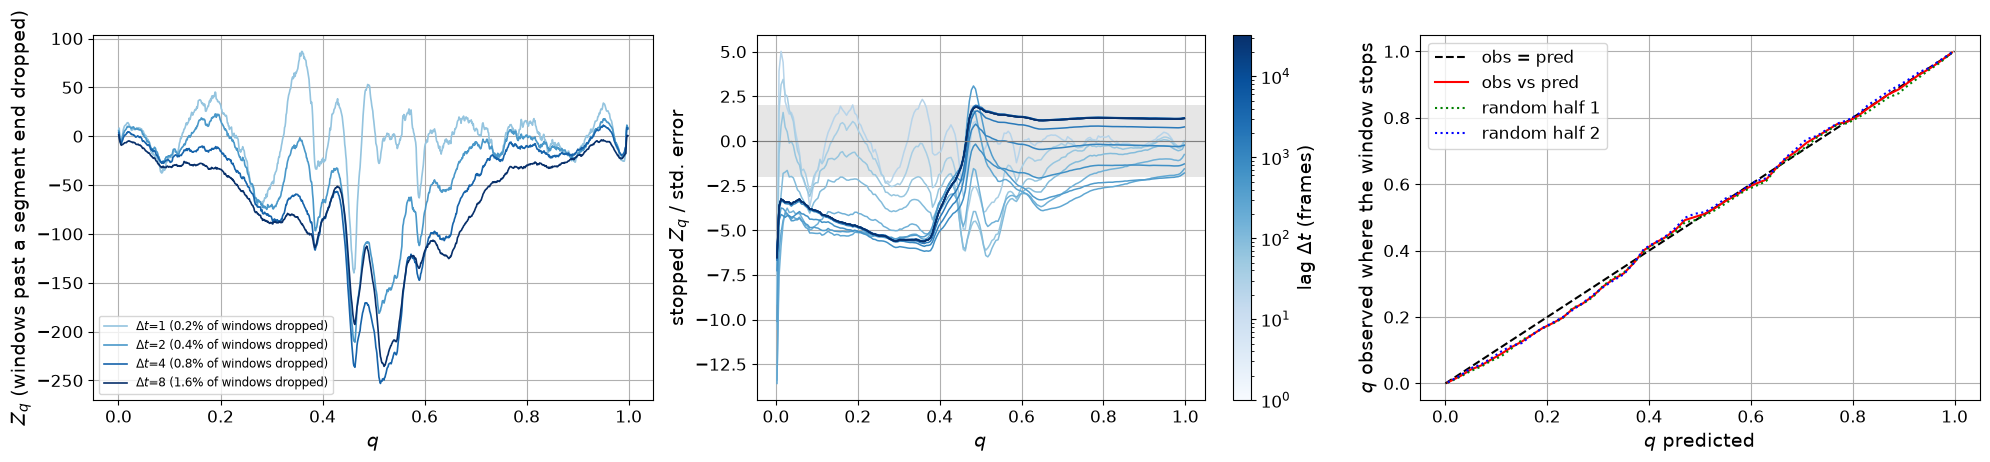

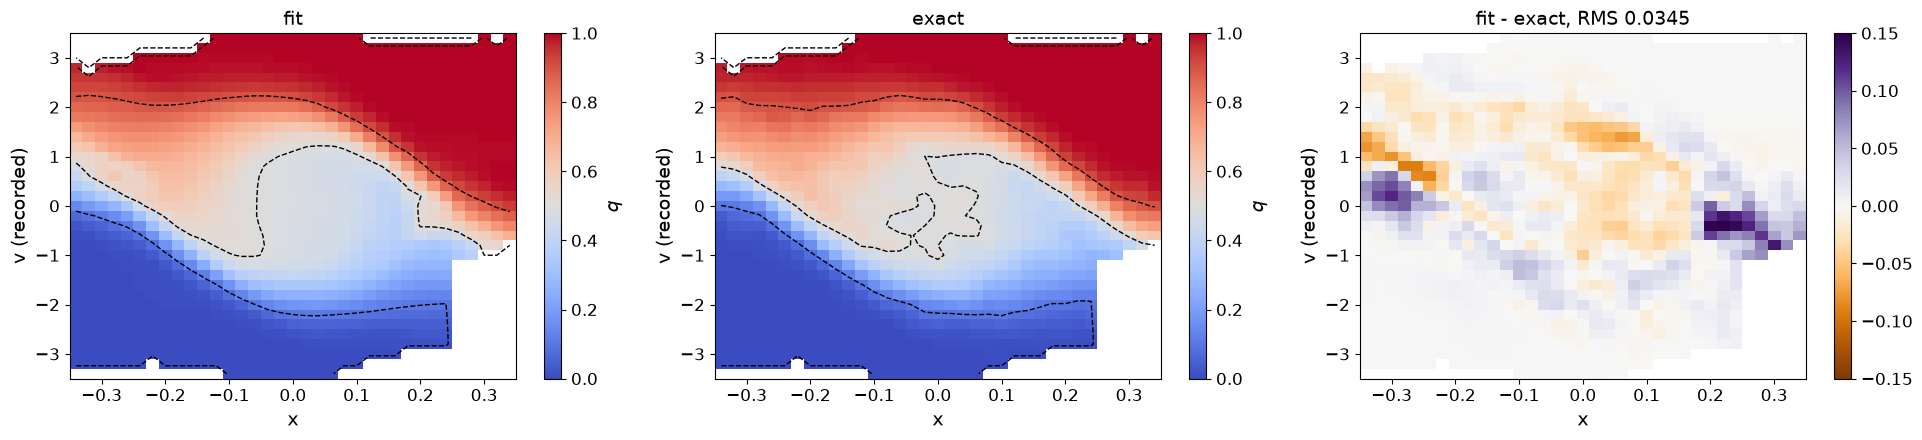

seed 1, 6000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.030 | max|z| at lags (1, 2, 4, 16, 64, 256):   3.7   4.9   6.2   5.2   5.5   5.9
#=6500, dr2=3178.78, zqs_z=29.9191, |dx|=0.0898639, time=32.2564
#=7000, dr2=2675.02, zqs_z=9.76682, |dx|=0.082212, time=64.7044
#=7500, dr2=2640.1, zqs_z=5.68601, |dx|=0.0322311, time=97.1268
#=8000, dr2=2962.66, zqs_z=28.5821, |dx|=0.0410142, time=129.553
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_well_staple/seeds_rev_recorded_lag1/seed1/it8000 ---


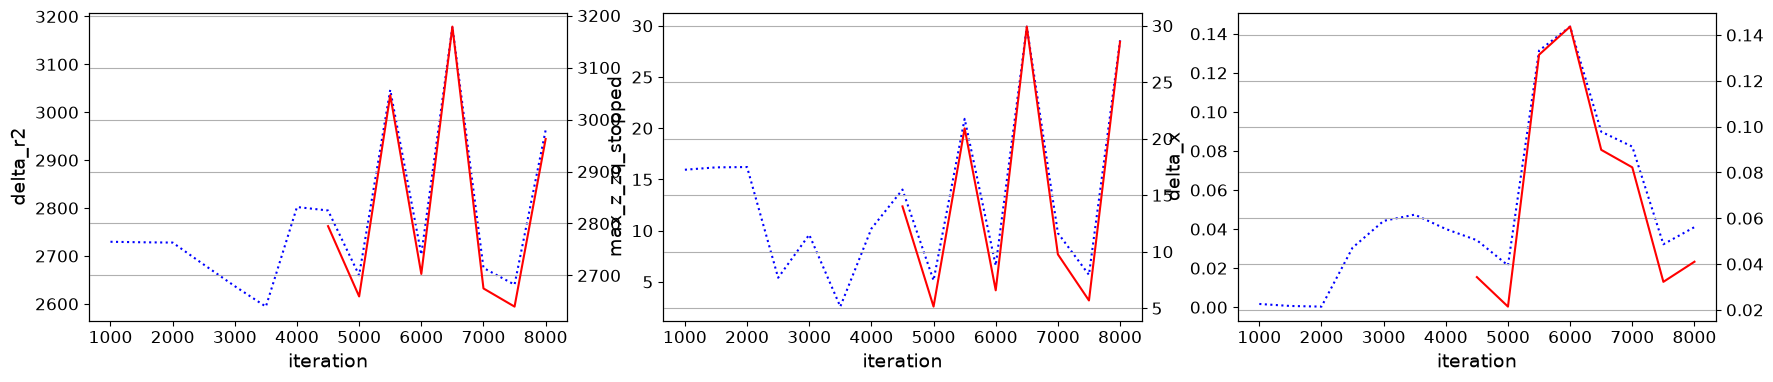

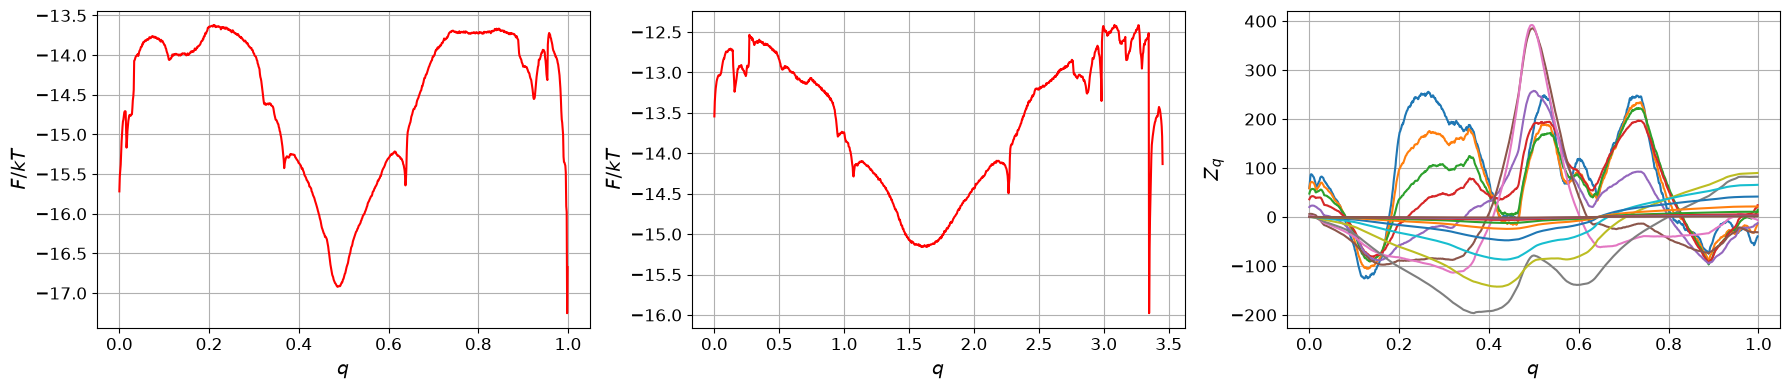

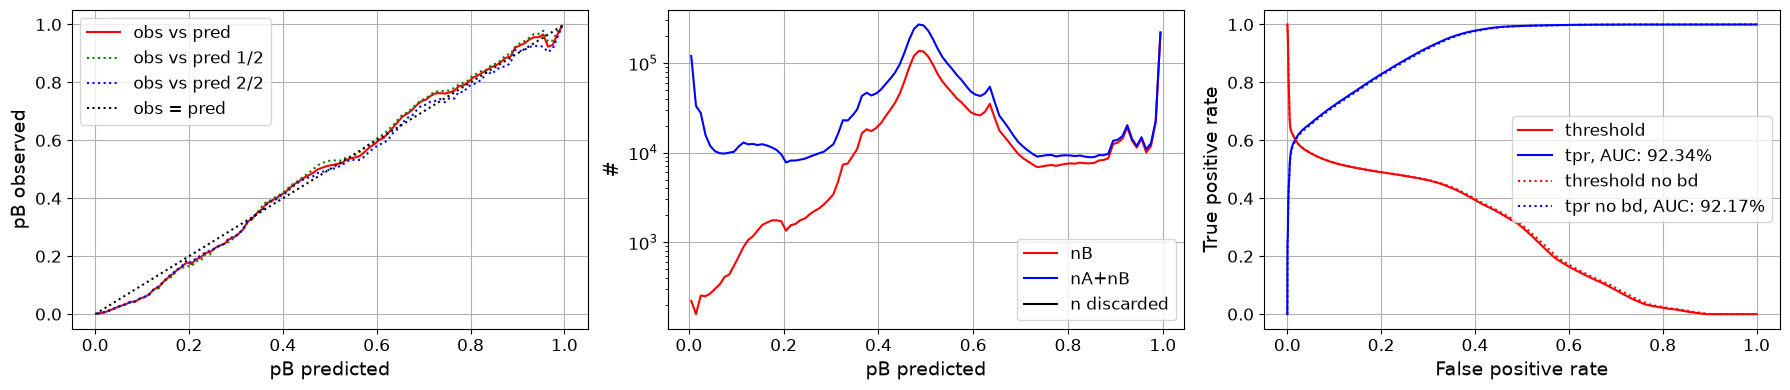

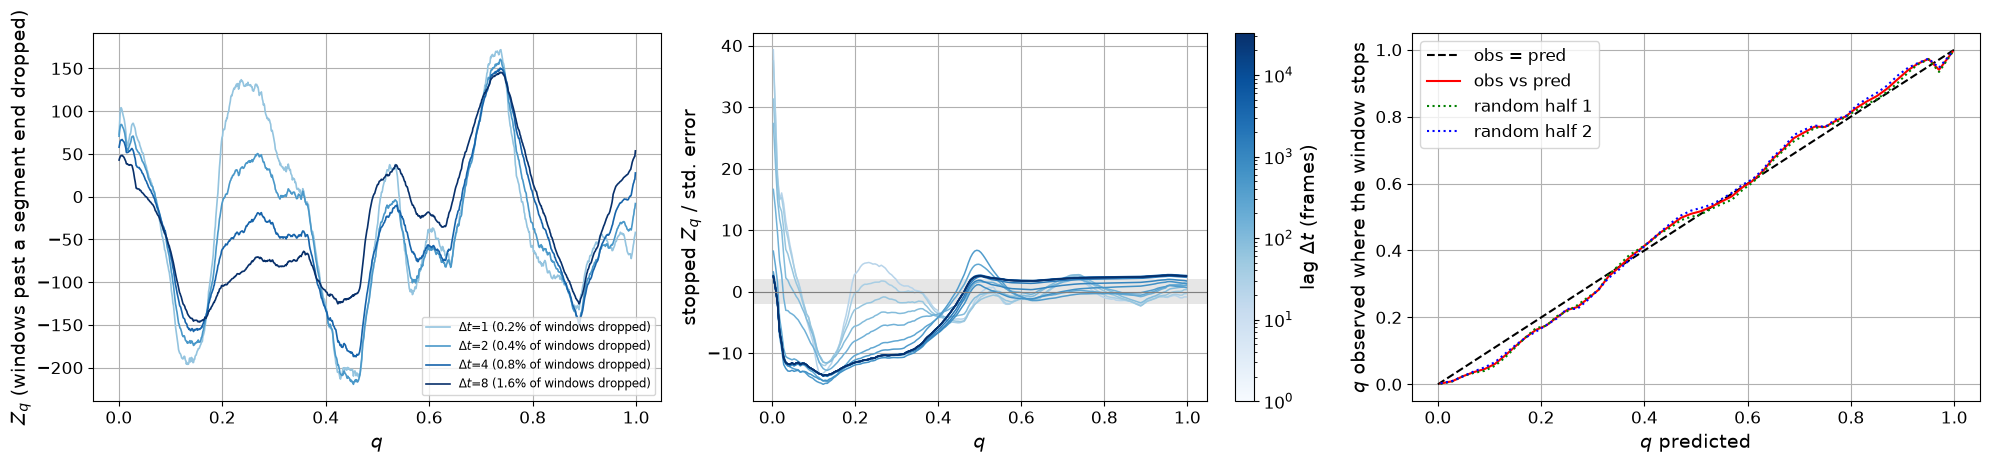

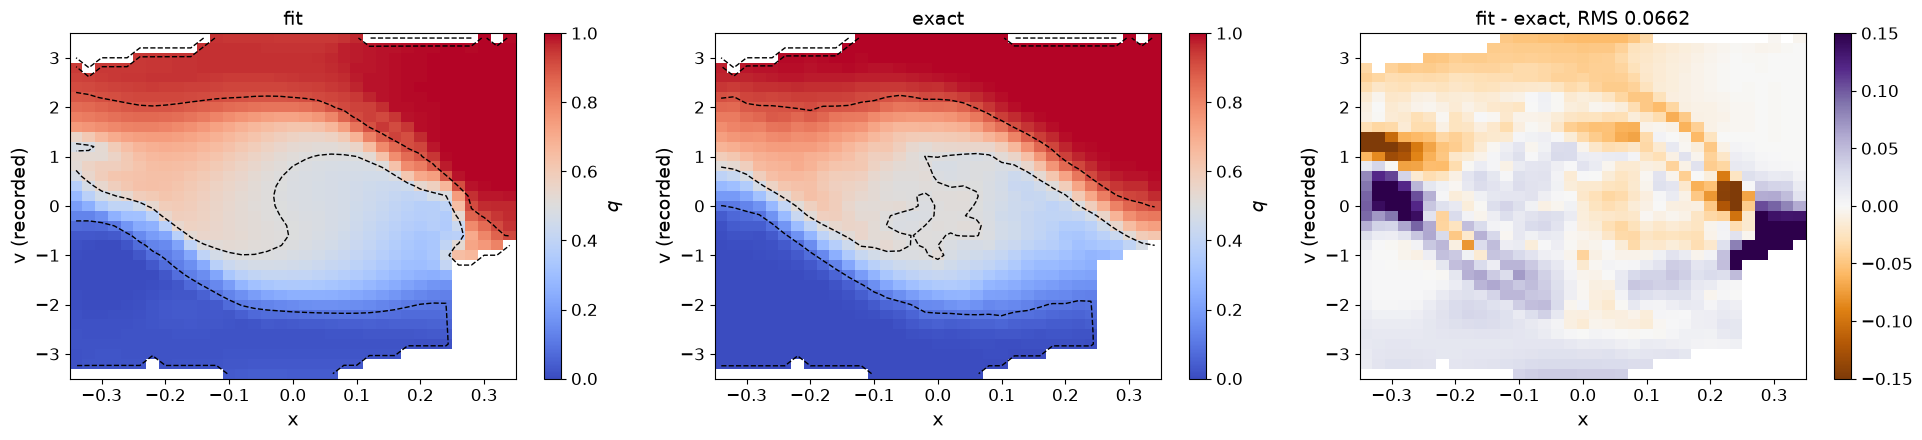

seed 1, 8000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.041 | max|z| at lags (1, 2, 4, 16, 64, 256):  14.3  13.0  11.6  12.8  15.1  13.8
#=8500, dr2=2829.74, zqs_z=21.0125, |dx|=0.0468323, time=32.1797
#=9000, dr2=2571.26, zqs_z=18.5963, |dx|=0.0300047, time=64.5996
#=9500, dr2=2986.99, zqs_z=22.8513, |dx|=0.052409, time=97.0062
#=10000, dr2=2676.82, zqs_z=20.461, |dx|=0.0873994, time=129.489
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_well_staple/seeds_rev_recorded_lag1/seed1/it10000 ---


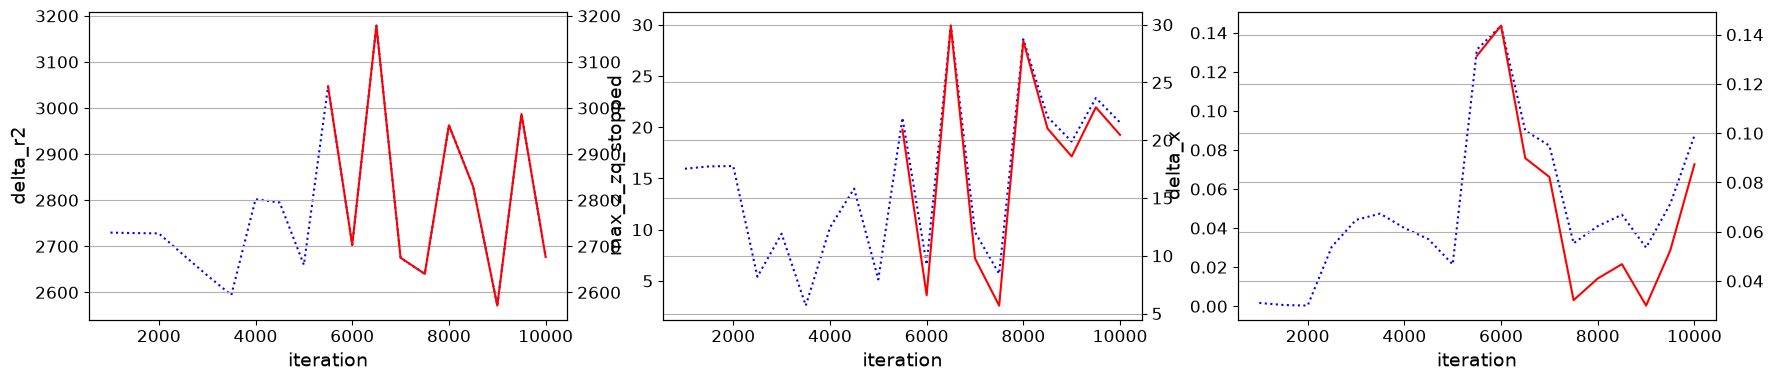

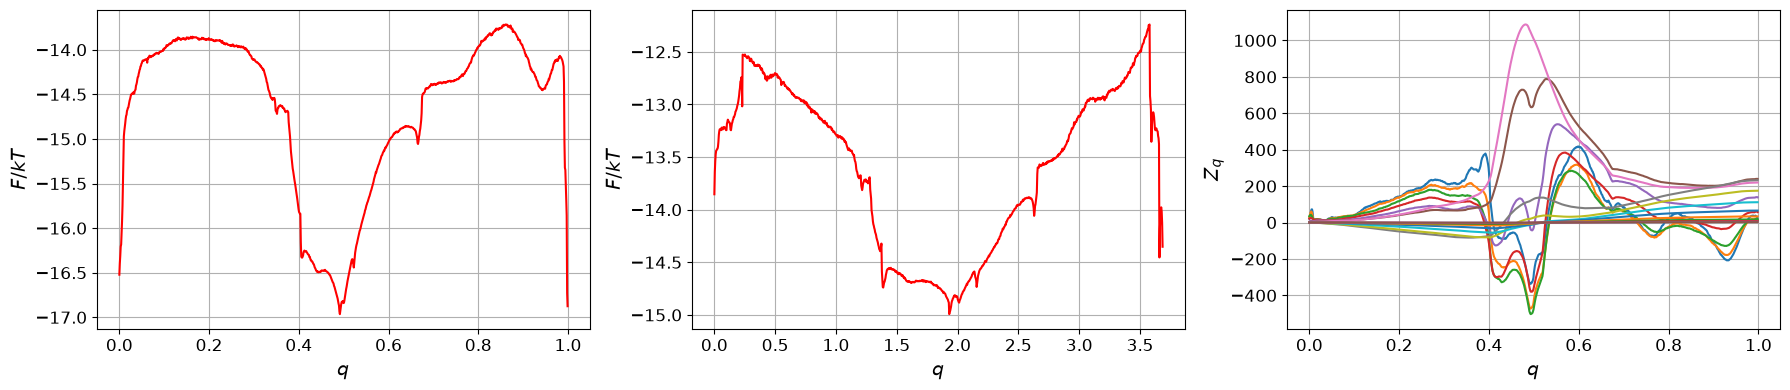

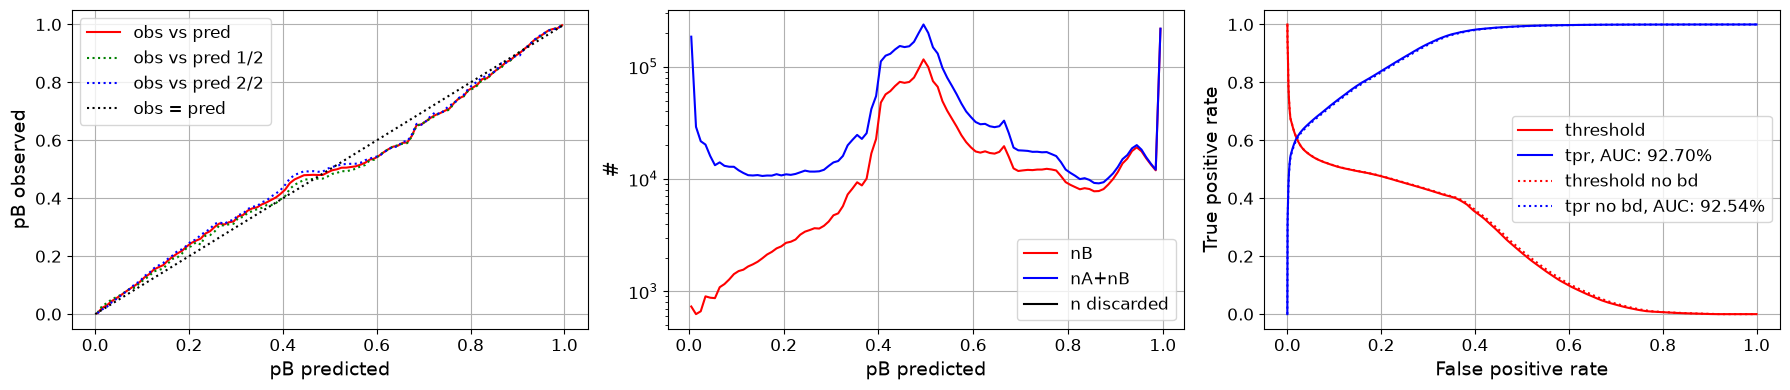

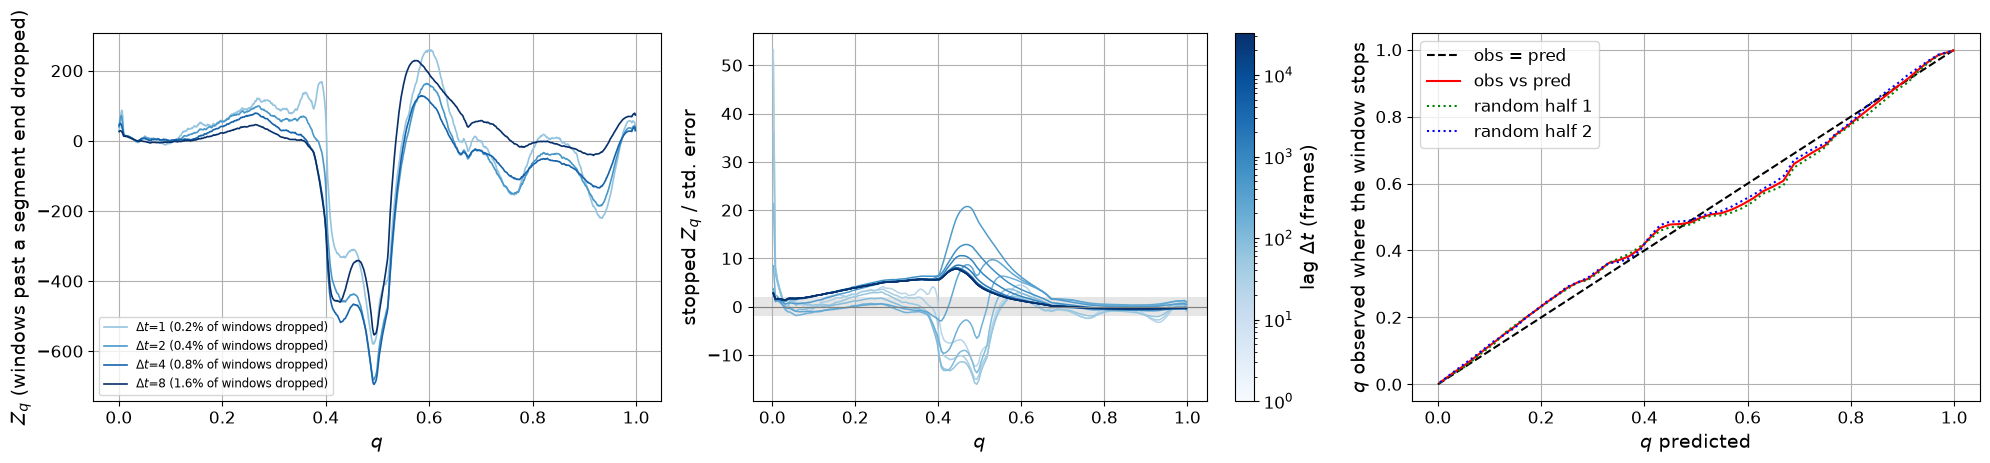

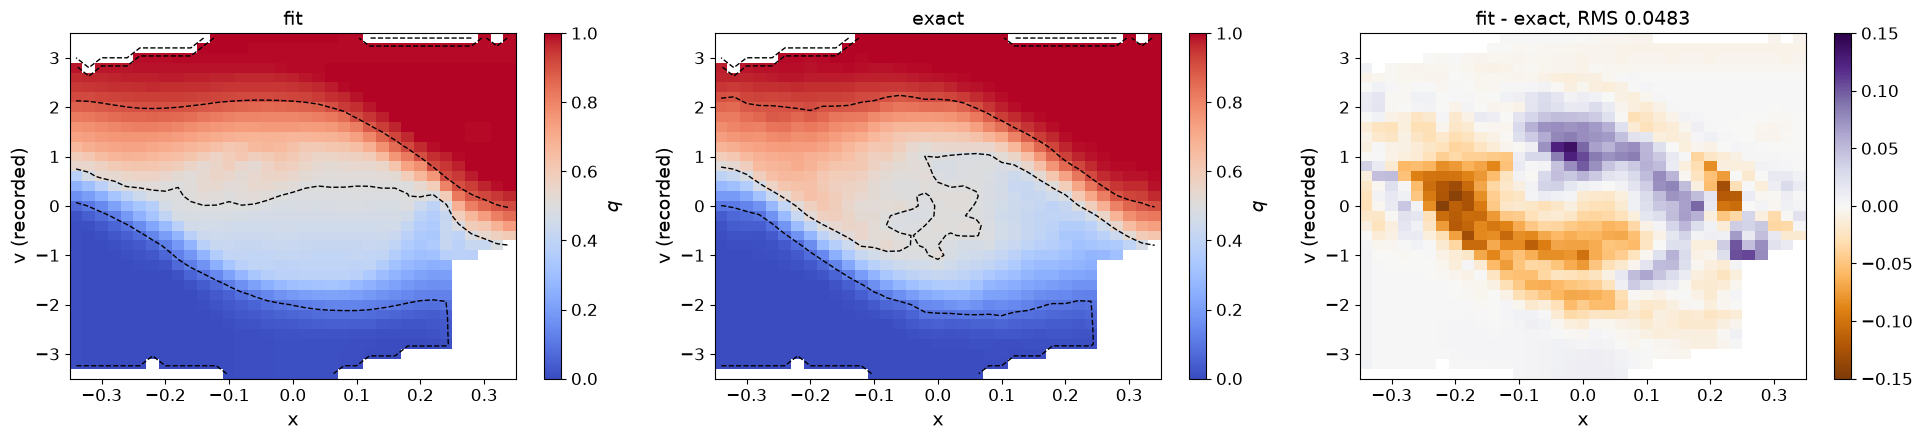

seed 1, 10000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.052 | max|z| at lags (1, 2, 4, 16, 64, 256):  12.3  15.0  16.1   9.6  20.7  10.6
#=10500, dr2=2724.72, zqs_z=7.37813, |dx|=0.0632948, time=32.1457
#=11000, dr2=2648.96, zqs_z=6.19517, |dx|=0.0386865, time=64.5764
#=11500, dr2=2665.61, zqs_z=6.19926, |dx|=0.0397422, time=97.0139
#=12000, dr2=2638.71, zqs_z=6.75019, |dx|=0.0122002, time=129.457
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_well_staple/seeds_rev_recorded_lag1/seed1/it12000 ---


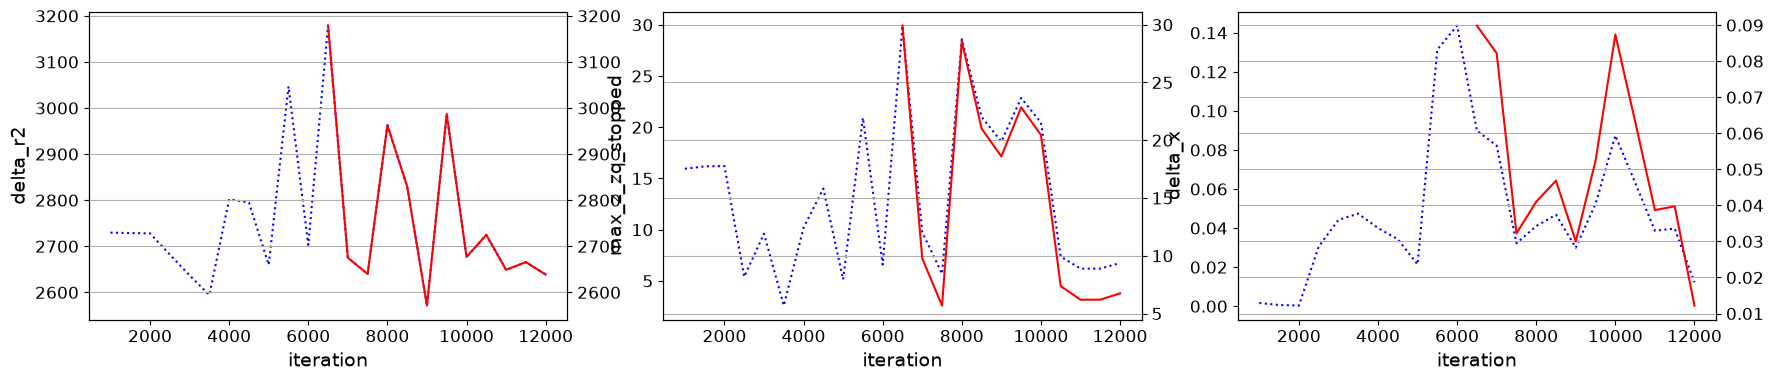

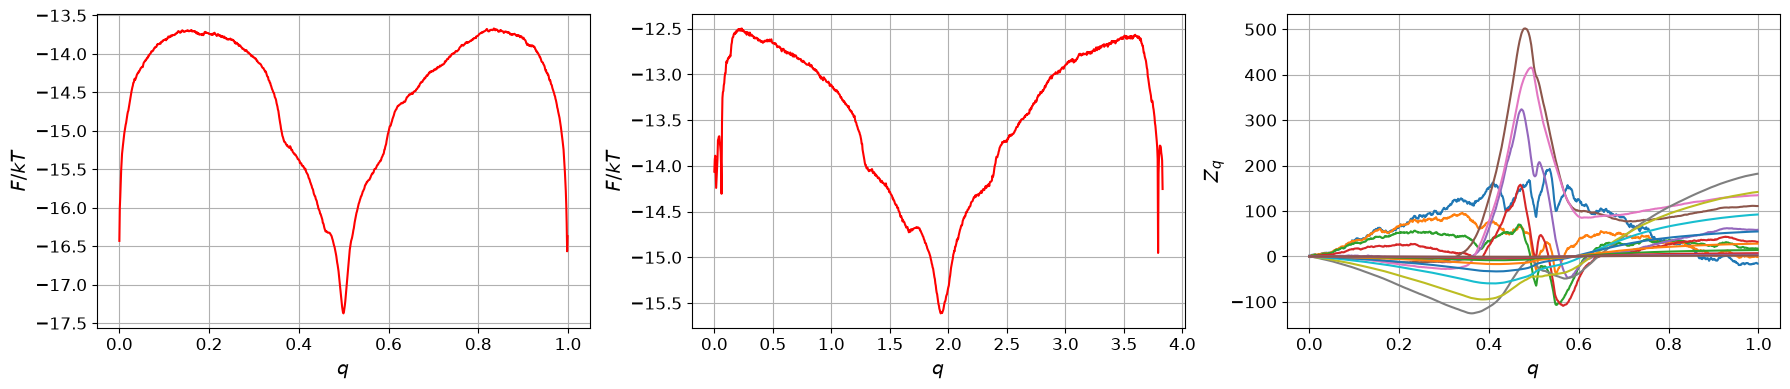

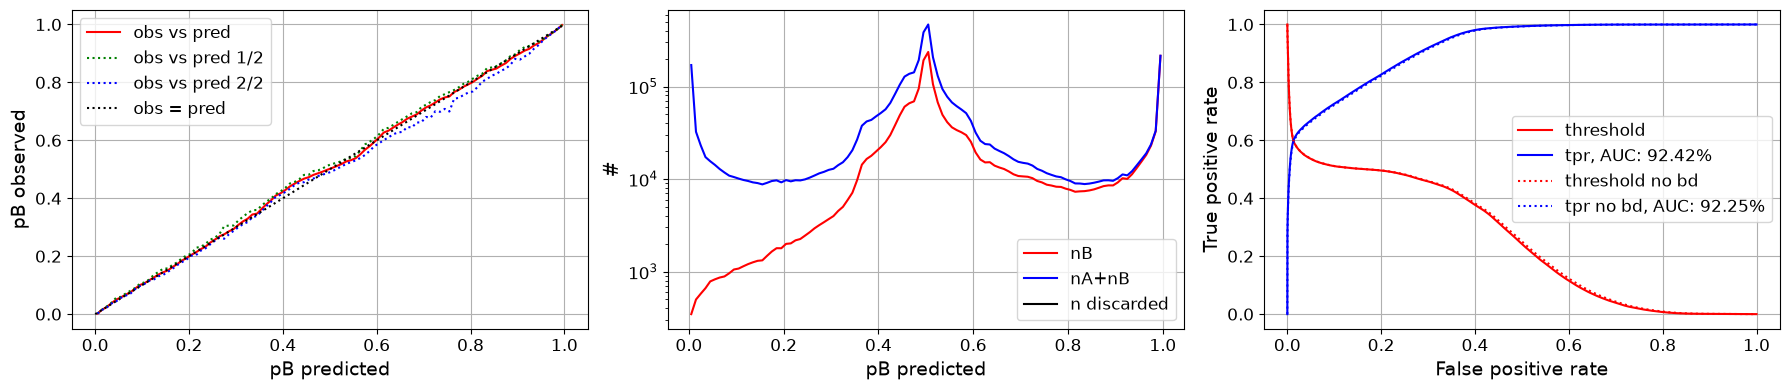

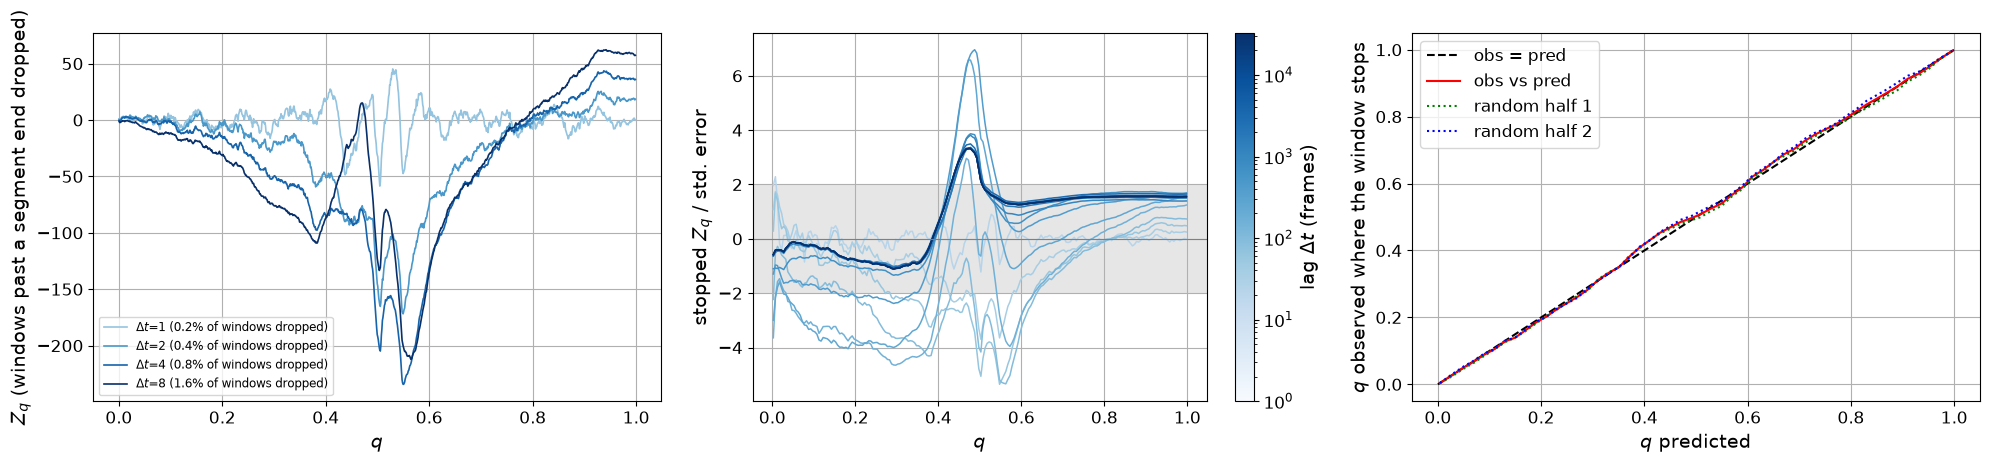

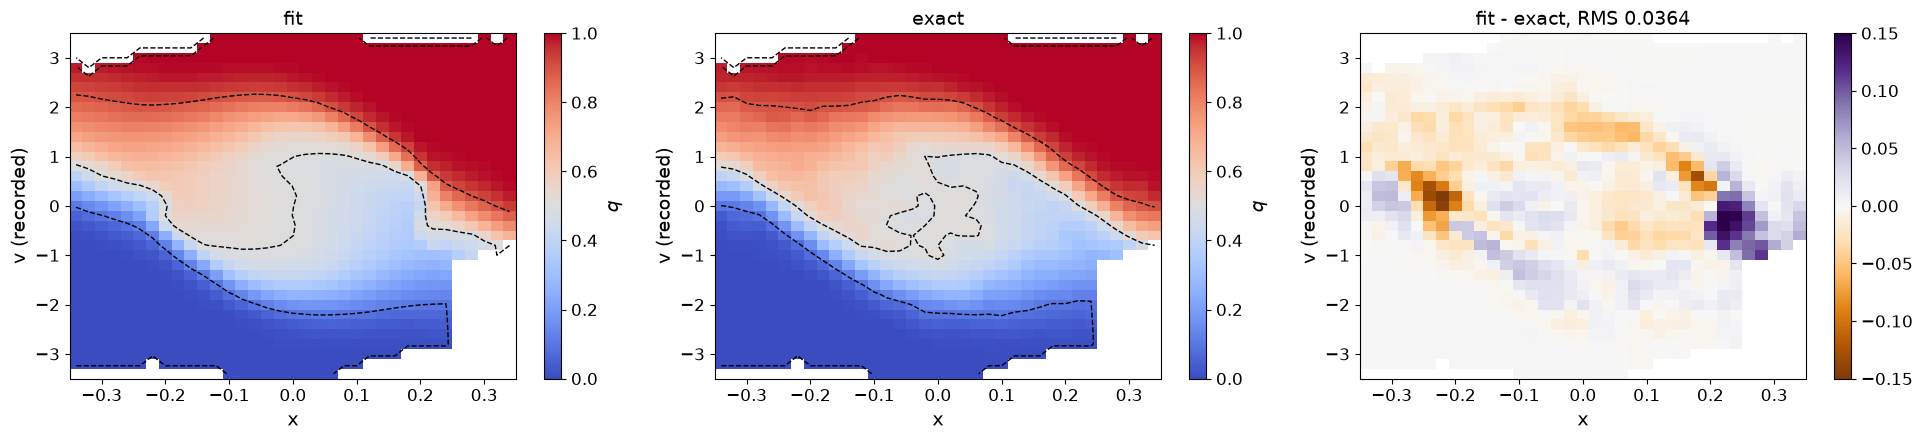

seed 1, 12000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.033 | max|z| at lags (1, 2, 4, 16, 64, 256):   1.2   3.7   5.4   4.6   7.0   3.8
seed 1: | RMS(fit - exact) 0.033 | max|z| at lags (1, 2, 4, 16, 64, 256):   1.2   3.7   5.4   4.6   7.0   3.8


In [6]:
VELOCITY = 'recorded'
FIT_LAG = 1
MAX_ITER = 10000                    # iterations per seed (after the warm-up)
SEEDS = [1]
CHUNK = 2000                       # iterations between shown and saved plots
ENVELOPE = 0.01                    # envelope_scale (library default)
GAMMA = 0.                        # regularization strength
WARMUP_ITER = 2000                    # optional warm-up (0 = off)
WARMUP_ENVELOPE = 1000000
WARMUP_GAMMA = GAMMA
WARMUP_CV = None                   # None: random CV; 0: x only; 1: v only
PLOTS = ('metrics', 'feps', 'obs_pred', 'tis')
TAG = f"{'rev' if REVERSED else 'fwd'}_{VELOCITY}_lag{FIT_LAG}"   # run settings, in the figure names

vel = v_rec if VELOCITY == 'recorded' else v_fd
Y = cp.asarray(np.c_[x, vel])
W = cp.asarray(data.path_weights)

if not hasattr(optimalrcs.nonparametrics, 'npneq_lag1'):
    optimalrcs.nonparametrics.npneq_lag1 = optimalrcs.nonparametrics.npneq     # keep the library's update
if FIT_LAG == 1:
    optimalrcs.nonparametrics.npneq = optimalrcs.nonparametrics.npneq_lag1
else:
    n = len(x); tau_np = cp.asnumpy(tau)
    u_np = np.minimum(np.arange(n) + FIT_LAG, tau_np)
    U = cp.asarray(u_np)
    STARTS = cp.asarray(np.flatnonzero(~b & (u_np > np.arange(n))))

    def npneq_lag(r_traj, fk, i_traj=None, gamma=0, stable=False, train_mask=None, chunk=None, w_traj=None, **kw):
        akj, bb = 0, 0
        for s0 in range(0, STARTS.size, 500_000):
            st = STARTS[s0:s0 + 500_000]
            fa, fb, wt = fk[:, st], fk[:, U[st]], W[st]
            akj = akj + fa @ (fb * wt - fa * (wt + gamma)).T
            bb = bb + fa @ (-(r_traj[U[st]] - r_traj[st]) * wt)
        al = cp.linalg.lstsq(akj, bb, rcond=None)[0]
        return cp.clip(r_traj + al @ fk, 0, 1)
    optimalrcs.nonparametrics.npneq = npneq_lag

import seed_runs

def make_q():
    q = optimalrcs.CommittorNE(
        boundary0=data.boundary0, boundary1=data.boundary1,
        i_traj=data.i_traj,            # piece (forward or mirrored)
        t_traj=data.t_traj,
        path_weights=data.path_weights,
        group_traj=data.group_traj,    # path: its two pieces are not independent
    )
    q.set_fixed_traj_length_trap(b, 2 ** 16)       # A/B ends as traps, for the metrics only
    return q

inside_r = ~b & (np.abs(v_rec) < 3.5)
def report(q):
    r = cp.asnumpy(q.r_traj)
    return (f'| RMS(fit - exact) {np.sqrt(np.mean((r[inside_r] - q_ref[inside_r]) ** 2)):.3f} '
            f'| max|z| at lags {LAGS}: {z_per_lag(r)}')

# after every chunk: mean q per (x, v) bin next to the exact committor and fit - exact, as in section 5
chunk_map = seed_runs.committor_map(
    [seed_runs.plane(x, np.linspace(-0.35, 0.35, 36), 'x', v_rec, np.linspace(-3.5, 3.5, 36), 'v (recorded)')],
    mask=inside_r, q_ref=q_ref)

results, q = seed_runs.run_seeds(
    optimalrcs, make_q,
    comp_y=lambda: Y[:, np.random.randint(2)],
    fit_kw=dict(basis_functions=lambda r_, y_, n_, f_: optimalrcs.basis_poly_ry(r_, y_, n_, f_),
                ny=6, print_step=500, save_min_delta_zq=False,
                metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'delta_x', 'time_elapsed')),
    seeds=SEEDS, max_iter=MAX_ITER, chunk=CHUNK, out_dir=f'{FIG_DIR}/seeds_{TAG}', envelope=ENVELOPE, gamma=GAMMA,
    warmup_iter=WARMUP_ITER, warmup_envelope=WARMUP_ENVELOPE, warmup_gamma=WARMUP_GAMMA,
    warmup_comp_y=None if WARMUP_CV is None else (lambda: Y[:, WARMUP_CV]),
    plots=PLOTS, plot_options=dict(feps_kw=dict(delta_t_sim=DT)),
    extra_plot={'q_x_v': chunk_map},
    report=report,
)

## 5. Comparison with the Exact Committor

RMS of fit − exact over all frames with |v| < 3.5, the mean error near A and near B for slow particles (|x| > 0.25, |v| < 0.5), and the worst stopped z per lag. Compare with the table at the top.

ERROR! Session/line number was not unique in database. History logging moved to new session 1586
forward + mirrored, recorded v, lag 1: RMS 0.033 | near A +0.009 | near B +0.025
max|z| at lags (1, 2, 4, 16, 64, 256):   1.2   3.7   5.4   4.6   7.0   3.8


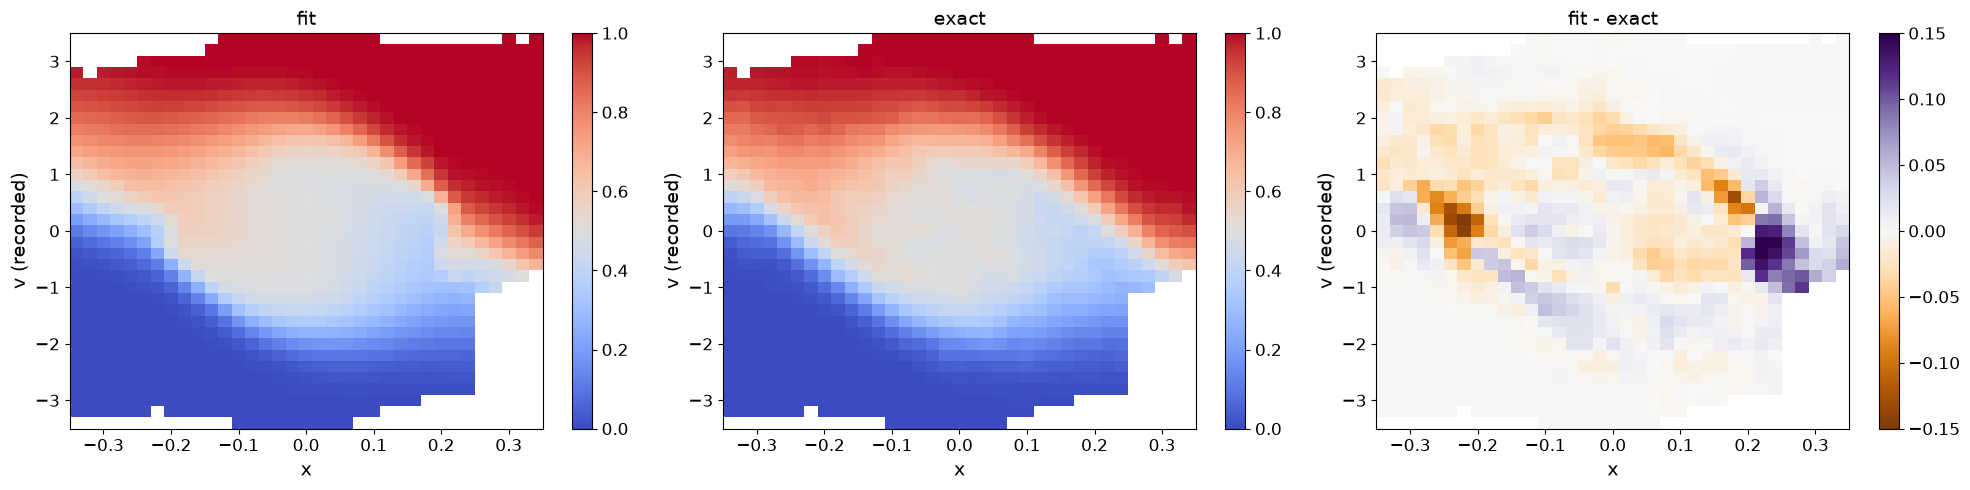

In [7]:
r = cp.asnumpy(q.r_traj)
inside = ~b & (np.abs(v_rec) < 3.5)
near_a = inside & (x < -0.25) & (np.abs(v_rec) < 0.5)
near_b = inside & (x > 0.25) & (np.abs(v_rec) < 0.5)
err = r - q_ref
print(f'{"forward + mirrored" if REVERSED else "forward"}, {VELOCITY} v, lag {FIT_LAG}: '
      f'RMS {np.sqrt(np.mean(err[inside] ** 2)):.3f} | near A {err[near_a].mean():+.3f} | near B {err[near_b].mean():+.3f}')
print(f'max|z| at lags {LAGS}: {z_per_lag(r)}')

e_x, e_v = np.linspace(-0.35, 0.35, 36), np.linspace(-3.5, 3.5, 36)
n_b = np.histogram2d(x[inside], v_rec[inside], [e_x, e_v])[0]
bm = lambda val: np.where(n_b >= 20, np.histogram2d(x[inside], v_rec[inside], [e_x, e_v], weights=val[inside])[0]
                          / np.maximum(n_b, 1), np.nan)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (m, title, cmap, lim) in zip(axes, [(bm(r), 'fit', 'coolwarm', (0, 1)), (bm(q_ref), 'exact', 'coolwarm', (0, 1)),
                                           (bm(err), 'fit - exact', 'PuOr', (-0.15, 0.15))]):
    im = ax.pcolormesh(e_x, e_v, m.T, cmap=cmap, vmin=lim[0], vmax=lim[1])
    ax.set(title=title, xlabel='x', ylabel='v (recorded)')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
save_fig(f'q_x_v_{TAG}')
plt.show()

## 6. Save Results

Uncomment to save the fit.

In [ ]:
# tag = f'{"rev_" if REVERSED else ""}{VELOCITY}_lag{FIT_LAG}'
# np.savez(f'{FIG}/well_check/fit_{tag}.npz', r=r)